# S06 · 前期降雨状态：ARP 与 CDD

> **Day 6 / 14** ｜ 对应论文章节 **3.5（Antecedent moisture state）**
>
> ⚠️ 模拟数据，结果仅用于验证流程。

---

## 学习目标

- 说清楚为什么「前期降雨」必须用**百分位**而不是毫米数
- 正确实现「严格前期」的滚动窗口
- 解释中性带（neutral band）存在的理由
- 验证 ARP 的构造是否自洽（均匀性检验）

---

## 1. 为什么要看前期降雨

Jackson et al. (2025) 的机制：

```
少雨 → 土壤湿度低 → 感热通量占比高 → 边界层增温 → 热浪
多雨 → 蒸发冷却 → 潜热通量占比高 → 抑制增温
```

**注意方向**：这不是「干旱导致热浪」这么简单。在**湿润地区（energy-limited）**，少雨→热浪；在**干旱地区（moisture-limited）**，多雨反而可能加剧湿热。马来西亚属于前者，这正是本研究的机制前提。

---

## 2. 加载并计算

In [1]:
for (p in c("00_setup.R", "notebooks/00_setup.R", "../00_setup.R")) {
  if (file.exists(p)) { source(p); break }
}


[00_setup.R] 已加载
  项目根目录 : C:/Users/User/Desktop/Jz/UTM/UGRP
  基准期     : 1985-2014
  阈值       : 90百分位, ±7天滑窗
  事件规则   : 最短 3 天, 合并间隔 ≤ 2 天
  干/湿切点  : ARP < 30 / > 50


In [2]:
d <- load_clean_daily()
STATION <- "Kuantan"
s <- d %>% filter(station == STATION) %>% arrange(date)
s <- s[format(s$date, "%m-%d") != "02-29", ]

ant <- antecedent_series(s)

cat("行数:", nrow(ant), "\n")
print(summary(ant[, c("rain_win_prev", "cdd", "arp")]))

行数: 16060 


 rain_win_prev         cdd              arp        
 Min.   :  0.00   Min.   : 0.000   Min.   :  0.00  
 1st Qu.: 14.40   1st Qu.: 0.000   1st Qu.: 25.11  
 Median : 28.80   Median : 1.000   Median : 50.22  
 Mean   : 33.77   Mean   : 1.766   Mean   : 50.14  
 3rd Qu.: 48.00   3rd Qu.: 3.000   3rd Qu.: 74.44  
 Max.   :182.70   Max.   :24.000   Max.   :100.00  
 NAs    :7                         NAs    :18      


---

## 3. 「严格前期」的滚动窗口

**关键定义**：事件起始日 `t` 的前期降雨 = `[t−7, t−1]` 的累计，**不含 `t` 当天**。

In [3]:
# rollsum(align="right") 在 i 处给的是 [i-6, i]；右移一格才是 [i-7, i-1]
rw_now  <- zoo::rollsum(s$rain, k = CFG$arp_window, align = "right", fill = NA)
rw_prev <- round(c(NA_real_, rw_now[-length(rw_now)]), 6)   # 抹掉 cumsum 的浮点噪声

# 与函数内部结果核对
stopifnot(all.equal(rw_prev, ant$rain_win_prev, tolerance = 1e-8))
cat("滚动窗口实现一致 ✓\n")

滚动窗口实现一致 ✓


> ⚠️ **为什么必须严格前期？**
> 如果窗口包含当天，就会出现反向因果：热浪当天往往不下雨（下沉增温抑制对流），于是「降雨少 → 热浪」这个关联有一部分是**热浪导致不下雨**，不是反过来。这会直接毁掉 RO2 的因果解释。

---

## 4. 为什么必须用百分位

In [4]:
# 同样的 12 mm，在东海岸和西海岸意味着什么？
mm_by_station <- d %>%
  group_by(station) %>%
  summarise(rain_q50 = round(median(rain, na.rm = TRUE), 2),
            rain_q90 = round(quantile(rain, 0.9, na.rm = TRUE), 2),
            .groups = "drop") %>%
  arrange(desc(rain_q90))

print(as.data.frame(mm_by_station), row.names = FALSE)

           station rain_q50 rain_q90
        Kuala_Krai        0    17.10
            Kluang        0    16.90
       Bayan_Lepas        0    16.80
        Kota_Bharu        0    16.80
           Kuantan        0    16.70
          Langkawi        0    16.70
              Ipoh        0    16.61
         Alor_Star        0    16.50
 Cameron_Highlands        0    16.50
           Chuping        0    16.50


> 📌 各站的降雨分位数差别很大。**用毫米数做阈值，等于假设所有站气候相同。**
> 用百分位（ARP, Antecedent Rainfall Percentile）= 「这个 7 日累计值在该站该季节历史上排第几」。

---

## 5. ARP 的构造：对每个日历日单独建参照分布

In [5]:
# 以 3 月 15 日为例，看参照集是怎么来的
target_doy <- ant$date[which.max(ant$cdd)]     # 挑一个最干的日期做例子
day_of_year <- as.integer(format(target_doy, "%j"))

ref_idx <- which(
  as.integer(format(ant$date, "%Y")) %in% CFG$base_years &
  circ_dist(as.integer(format(ant$date, "%j")), day_of_year) <= CFG$halfwin &
  !is.na(ant$rain_win_prev)
)

cat("示例日期:", format(target_doy), " (doy =", day_of_year, ")\n")
cat("参照样本数:", length(ref_idx), "\n")
cat("参照分布的 30/50 百分位:",
    round(quantile(ant$rain_win_prev[ref_idx], c(0.30, 0.50)), 2), "mm\n")

示例日期: 2005-08-11  (doy = 223 )


参照样本数: 450 


参照分布的 30/50 百分位: 11 20.7 mm


In [6]:
# 把这一天前后 10 天的完整链条打印出来
i <- which(ant$date == target_doy)
print(ant[(i - 9):i, c("date", "rain", "rain_win_prev", "cdd", "arp", "state")],
      row.names = FALSE)

       date rain rain_win_prev cdd      arp state
 2005-08-02  0.0           0.5  15 6.444444   dry
 2005-08-03  0.0           0.5  16 6.666667   dry
 2005-08-04  0.0           0.5  17 7.111111   dry
 2005-08-05  0.0           0.5  18 7.333333   dry
 2005-08-06  0.0           0.5  19 7.555556   dry
 2005-08-07  0.0           0.5  20 7.777778   dry
 2005-08-08  0.0           0.5  21 7.777778   dry
 2005-08-09  0.0           0.0  22 6.666667   dry
 2005-08-10  0.0           0.0  23 7.333333   dry
 2005-08-11  1.5           0.0  24 8.000000   dry


> 🔍 **看最后一行**：`rain_win_prev` 是前 7 天的累计（不含当天），`cdd` 是连续干日数，`arp` 是前 7 天累计值在参照分布中的位置。
> `arp` 接近 0 意味着「过去 7 天是同季历史上最干的」。
>
> 还要注意 `08-07` 与 `08-08` 的 ARP 完全相同（`7.777778`）—— 那两天窗口内同样是 0.5 mm。
> **平局（ties）在 ARP 里是常态**，不是异常。§6 会讲它为什么重要。

---

## 6. 自洽性检验：ARP 在基准期内应当近似均匀

百分位变换有一个可检验的推论：**如果参照分布用对了，基准期内的 ARP 应当近似服从 U(0,100)。**
这叫做**概率积分变换（PIT）的均匀性**，也是 S09 拟合边缘分布时要用的同一个原理。

In [7]:
base_arp <- ant$arp[as.integer(format(ant$date, "%Y")) %in% CFG$base_years]
base_arp <- base_arp[!is.na(base_arp)]

ks <- suppressWarnings(ks.test(base_arp / 100, "punif"))
cat(sprintf("n = %d\n", length(base_arp)))
cat(sprintf("KS: D = %.4f, p = %.4f\n", ks$statistic, ks$p.value))

n = 10943


KS: D = 0.0217, p = 0.0001


In [8]:
# 只看 p 值会被样本量骗。数一数每个十分位实际占多少：
dec <- cut(base_arp, breaks = seq(0, 100, 10), include.lowest = TRUE)
print(round(table(dec) / length(base_arp), 4))

dec
  [0,10]  (10,20]  (20,30]  (30,40]  (40,50]  (50,60]  (60,70]  (70,80] 
  0.0880   0.1085   0.0989   0.1035   0.0990   0.0999   0.1021   0.0990 
 (80,90] (90,100] 
  0.1010   0.1002 


> 🔍 **这里有一个必须学会的判读习惯。**
>
> 先看 `D`（效应量）：它等于「经验分布与均匀分布的最大垂直距离」，单位是**百分点**。
> `D = 0.02` 意味着最差的那个百分位只偏了 **2 个百分点** —— 在 90 百分位阈值的语境下完全无害。
>
> 再看 `p`：n ≈ 11000，KS 的临界值约为 `1.36/√n ≈ 0.013`。**这么小的 D 也会「显著」。**
> `p < 0.05` 在这个样本量下**不等于**「构造有问题」，它只说明「偏离不为零」。
>
> 上面那张十分位表更有信息量：除了最低的 `[0,10]` 一格偏低，其余都贴着 10%。
> 偏低的原因是 `ecdf()` 对**平局（ties）**的处理 —— 前 7 天完全无雨的日子（基准期内约 3.8%）
> 全部落在同一个累计概率上，`ecdf` 取「≤」定义，把它们整体推到那一点。
>
> **结论**：ARP 的构造自洽，可以在 RO2 里用；但这个平局问题在 S09 会以更严格的方式回来 ——
> 那时我们对离散变量（duration）用**随机化 PIT**，正是为了修掉它。

> ⚠️ 如果 `D` 超过 0.1（10 个百分点），那才是真有问题：通常是参照窗口太窄、或者环形距离写错。

---

## 7. 状态切分与中性带

In [9]:
cat("切点: dry <", CFG$arp_dry, " | neutral", CFG$arp_dry, "-", CFG$arp_wet,
    "| wet >", CFG$arp_wet, "\n\n")
print(table(ant$state, useNA = "ifany"))
print(round(prop.table(table(ant$state, useNA = "ifany")), 3))

切点: dry < 30  | neutral 30 - 50 | wet > 50 




    dry neutral     wet    <NA> 
   4777    3229    8036      18 



    dry neutral     wet    <NA> 
  0.297   0.201   0.500   0.001 


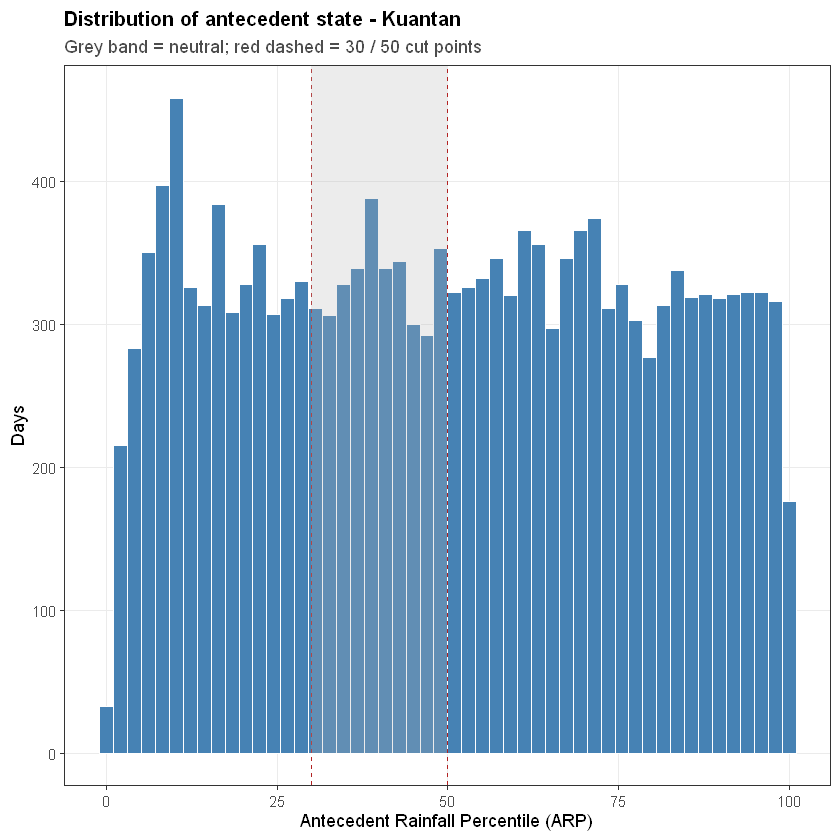

In [10]:
p_arp <- ggplot(ant[!is.na(ant$arp), ], aes(arp)) +
  geom_histogram(bins = 50, fill = "steelblue", colour = "white") +
  geom_vline(xintercept = c(CFG$arp_dry, CFG$arp_wet),
             linetype = "dashed", colour = "firebrick") +
  annotate("rect", xmin = CFG$arp_dry, xmax = CFG$arp_wet,
           ymin = 0, ymax = Inf, fill = "grey70", alpha = 0.25) +
  labs(x = "Antecedent Rainfall Percentile (ARP)", y = "Days",
       title = paste("Distribution of antecedent state -", STATION),
       subtitle = "Grey band = neutral; red dashed = 30 / 50 cut points") +
  theme_paper()

save_fig(p_arp, "S06_arp_distribution", 6.5, 4)
p_arp

> 🔍 **为什么要有中性带？**
> 如果直接把 ARP = 50 切开，那么 ARP = 49.9 和 50.1 会被分到「干」和「湿」两组 —— 但这两个日子的物理条件几乎一样。差异全是噪声。
> 中性带（30–50）把这部分模糊样本剔除，让 dry 与 wet 的对比有实际意义。
> **代价**是损失约 20% 的样本 —— 必须在方法章写明，并在 S14 做切点敏感性分析。

---

## 8. ARP 与 CDD 的关系

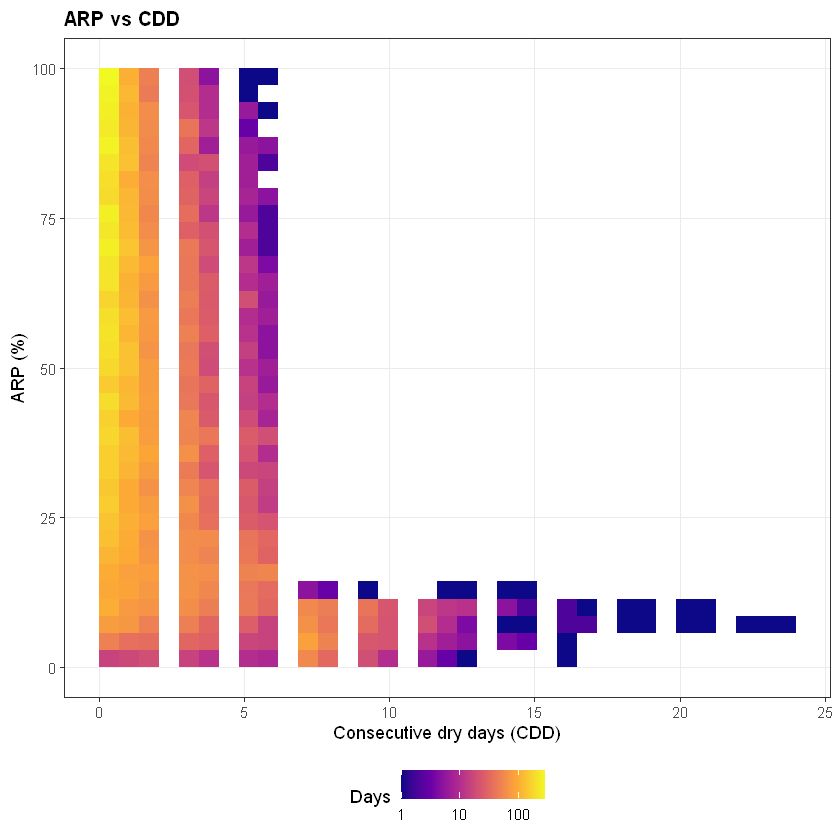

In [11]:
p_cd <- ggplot(ant[!is.na(ant$arp), ], aes(cdd, arp)) +
  geom_bin2d(bins = 35) +                 # ggplot2 自带，不需要额外装 hexbin
  scale_fill_viridis_c(trans = "log10", option = "C") +
  labs(x = "Consecutive dry days (CDD)", y = "ARP (%)",
       title = "ARP vs CDD", fill = "Days") +
  theme_paper()

save_fig(p_cd, "S06_arp_vs_cdd", 6.5, 4)
p_cd

> 📌 两者负相关但不完全共线：CDD 只看「连续无雨」，ARP 看「7 日累计量」。
> ARP 更细（能区分「连续小毛毛雨」和「完全不下」），CDD 更直观。论文里可以两个都报告，用 ARP 做主分析。

---

## 9. 挂到事件上：事件层的状态分布

In [12]:
cat_ev <- load_catalogue()

cat("事件层状态分布：\n")
print(table(cat_ev$defn, cat_ev$state, useNA = "ifany"))

cat("\n行百分比：\n")
print(round(prop.table(table(cat_ev$defn, cat_ev$state), 1) * 100, 1))

事件层状态分布：


       
        dry neutral wet
  Tmax  538     219 293
  Tmin  280      93 150
  Twmax 463     176 273



行百分比：


       
         dry neutral  wet
  Tmax  51.2    20.9 27.9
  Tmin  53.5    17.8 28.7
  Twmax 50.8    19.3 29.9


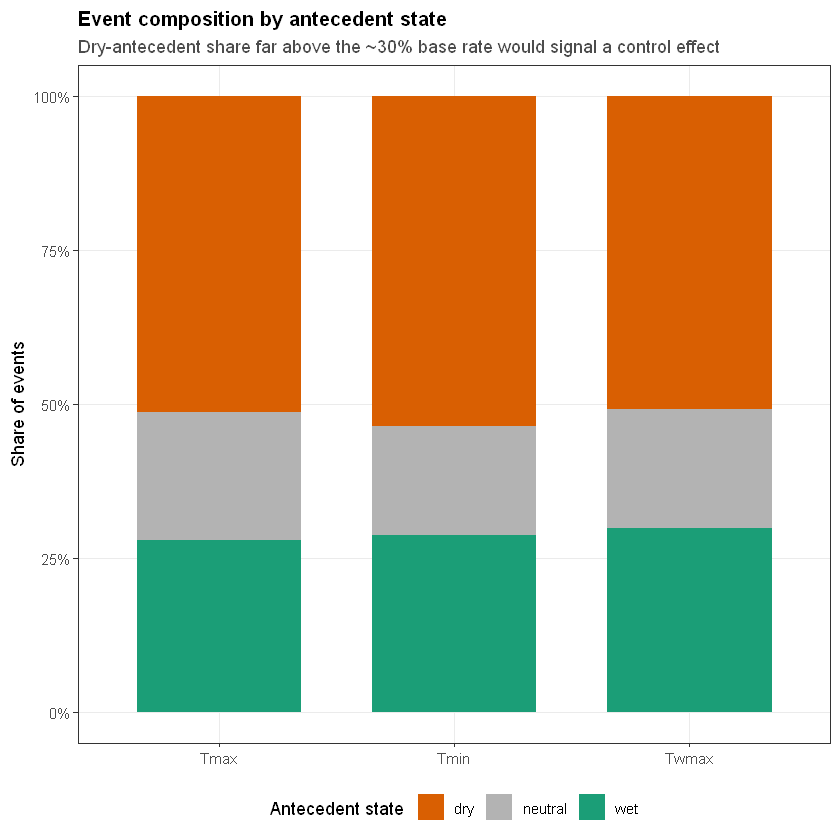

In [13]:
state_df <- as.data.frame(table(defn = cat_ev$defn, state = cat_ev$state))
names(state_df)[3] <- "n"

p_state <- ggplot(state_df, aes(defn, n, fill = state)) +
  geom_col(position = "fill", width = 0.7) +
  scale_fill_manual(values = c(dry = "#D95F02", neutral = "grey70", wet = "#1B9E77")) +
  scale_y_continuous(labels = scales::percent) +
  labs(x = NULL, y = "Share of events", fill = "Antecedent state",
       title = "Event composition by antecedent state",
       subtitle = "Dry-antecedent share far above the ~30% base rate would signal a control effect") +
  theme_paper()

save_fig(p_state, "S06_state_composition", 6.5, 4)
p_state

> 🔍 **怎么读这张图**：全体日子里 dry 只占 **约 30%**（见 §7 的表），但事件里 dry 占到 **51–54%**。
> 也就是说，干前期条件下的事件数几乎是「按天数比例应有的」两倍 —— **少雨条件显著提高了热浪发生的概率**。
> 这个 52% vs 30% 的对比，就是 RO2 的直观版本。
>
> ⚠️ 但这还只是**描述**。事件之间不独立（同一个热浪可能被拆成几段）、干湿期的日历分布不均、
> 样本量差异都会影响这个比例。**要下统计结论，必须走 S07 的推断框架。**

---

## 10. 常见错误

| 错误 | 后果 |
|---|---|
| 窗口包含当天 | 反向因果污染 |
| 用毫米数而不归一化 | 站点间不可比 |
| 用全时段（非基准期）建参照分布 | 与气候变化混淆 |
| 不做环形距离 | 年初年尾的 ARP 失真 |
| 没有中性带 | dry/wet 差异被噪声稀释 |
| ARP 不检查均匀性 | 构造错误无法被发现 |

---

## 11. 自检问题

<details>
<summary>Q1：为什么 ARP 要在「±7 天的日历窗」里算，而不是全年？</summary>

因为降雨有强季节性（东北季风）。1 月的 20 mm 和 7 月的 20 mm 意义完全不同。在日历窗里归一化，等于自动去季节化。
</details>

<details>
<summary>Q2：ARP = 0 是什么意思？会不会太多？</summary>

意味着前 7 天累计降雨低于基准期该日历窗内的所有值 —— 即「最干」。如果 ARP = 0 的日子超过 1%，说明参照分布有平局（很多 0 mm 的天），此时应该用随机化排名或改用 CDD。
</details>

<details>
<summary>Q3：为什么中性带要取 30–50 而不是对称的 40–60？</summary>

这纯粹是设计选择。30/50 让 dry 组更「干」（前 30%），wet 组是「中位以上」（后 50%），两组样本量相对均衡。如果取 40/60，dry 组样本更多但「干」的强度更弱。这个选择会影响 Δτ 的大小，S14 要做敏感性分析。
</details>

<details>
<summary>Q4：CDD 和 ARP 高度负相关，为什么两个都要？</summary>

CDD 只看「是否下雨」，不看雨量。连续 10 天每天 0.5 mm 的毛毛雨，CDD = 0 但土壤仍然很干。ARP 用累计量，能捕捉这种情况。反之 CDD 对「连续无雨」这个物理过程更直接。两者互补。
</details>

---

## 下一步

**S07 · RO2**：把「少雨 → 热浪更多」从直觉变成可检验的统计陈述。